# DistilBERT: real and synthetic training mixtures

Train separate models with 0%, 25%, 50%, 75%, and 100% synthetic data. Every training set has 8,000 examples and 2,000 per class. All runs use learning rate 5e-5, weight decay 0.01, one epoch, and seed 42. The shared validation set is checked during training; the original test set is evaluated once after each run. Each final model is saved separately.

In [1]:
from pathlib import Path
import torch

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
assert torch.cuda.is_available(), 'CUDA GPU required'
print('GPU:', torch.cuda.get_device_name(0))
print('Synthetic source:', PROJECT_ROOT / 'data' / 'synthetic' / 'final_8000.csv')

GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Synthetic source: E:\VGTU\5 semester\Natural Language Processing\lab 4\data\synthetic\final_8000.csv


In [2]:
import runpy

_ = runpy.run_path(str(PROJECT_ROOT / 'src' / 'train_mixtures.py'), run_name='__main__')

E:\VGTU\5 semester\Natural Language Processing\lab 4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Reusing completed mixture: 0 %


Reusing completed mixture: 25 %


Reusing completed mixture: 50 %


Reusing completed mixture: 75 %


Reusing completed mixture: 100 %



Final results table:


 synthetic_percentage  real_count  synthetic_count  train_loss  validation_loss  validation_accuracy  validation_macro_precision  validation_macro_recall  validation_macro_f1  test_loss  test_accuracy  test_macro_precision  test_macro_recall  test_macro_f1
                    0        8000                0    0.358692         0.294512               0.9105                    0.910606                   0.9105             0.910479   0.273918       0.907500              0.907154           0.907500       0.907253
                   25        6000             2000    0.318119         0.342933               0.8935                    0.894132                   0.8935             0.893718   0.305438       0.908684              0.908533           0.908684       0.908526
                   50        4000             4000    0.256386         0.374414               0.8880                    0.888945                   0.8880             0.888183   0.340295       0.899737              0.900605       

Saved: E:\VGTU\5 semester\Natural Language Processing\lab 4\results\mixture_training\mixture_metrics.csv


In [3]:
import pandas as pd

results_dir = PROJECT_ROOT / 'results' / 'mixture_training'
table = pd.read_csv(results_dir / 'mixture_metrics.csv')
assert table['synthetic_percentage'].tolist() == [0, 25, 50, 75, 100]
display(table.round(4))

,synthetic_percentage,real_count,synthetic_count,train_loss,validation_loss,validation_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1,test_loss,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1
0,0,8000,0,0.3587,0.2945,0.9105,0.9106,0.9105,0.9105,0.2739,0.9075,0.9072,0.9075,0.9073
1,25,6000,2000,0.3181,0.3429,0.8935,0.8941,0.8935,0.8937,0.3054,0.9087,0.9085,0.9087,0.9085
2,50,4000,4000,0.2564,0.3744,0.8880,0.8889,0.8880,0.8882,0.3403,0.8997,0.9006,0.8997,0.8998
3,75,2000,6000,0.1936,0.4226,0.8840,0.8842,0.8840,0.8840,0.3933,0.8908,0.8905,0.8908,0.8906
4,100,0,8000,0.0890,1.1313,0.7895,0.8161,0.7895,0.7749,1.1917,0.7820,0.8115,0.7820,0.7641


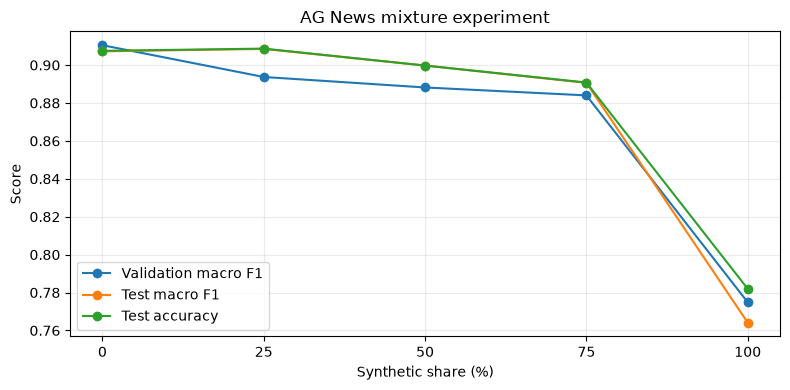

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(table['synthetic_percentage'], table['validation_macro_f1'], marker='o', label='Validation macro F1')
ax.plot(table['synthetic_percentage'], table['test_macro_f1'], marker='o', label='Test macro F1')
ax.plot(table['synthetic_percentage'], table['test_accuracy'], marker='o', label='Test accuracy')
ax.set(xlabel='Synthetic share (%)', ylabel='Score', title='AG News mixture experiment')
ax.set_xticks([0, 25, 50, 75, 100])
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(results_dir / 'mixture_metrics.png', dpi=160)
plt.show()

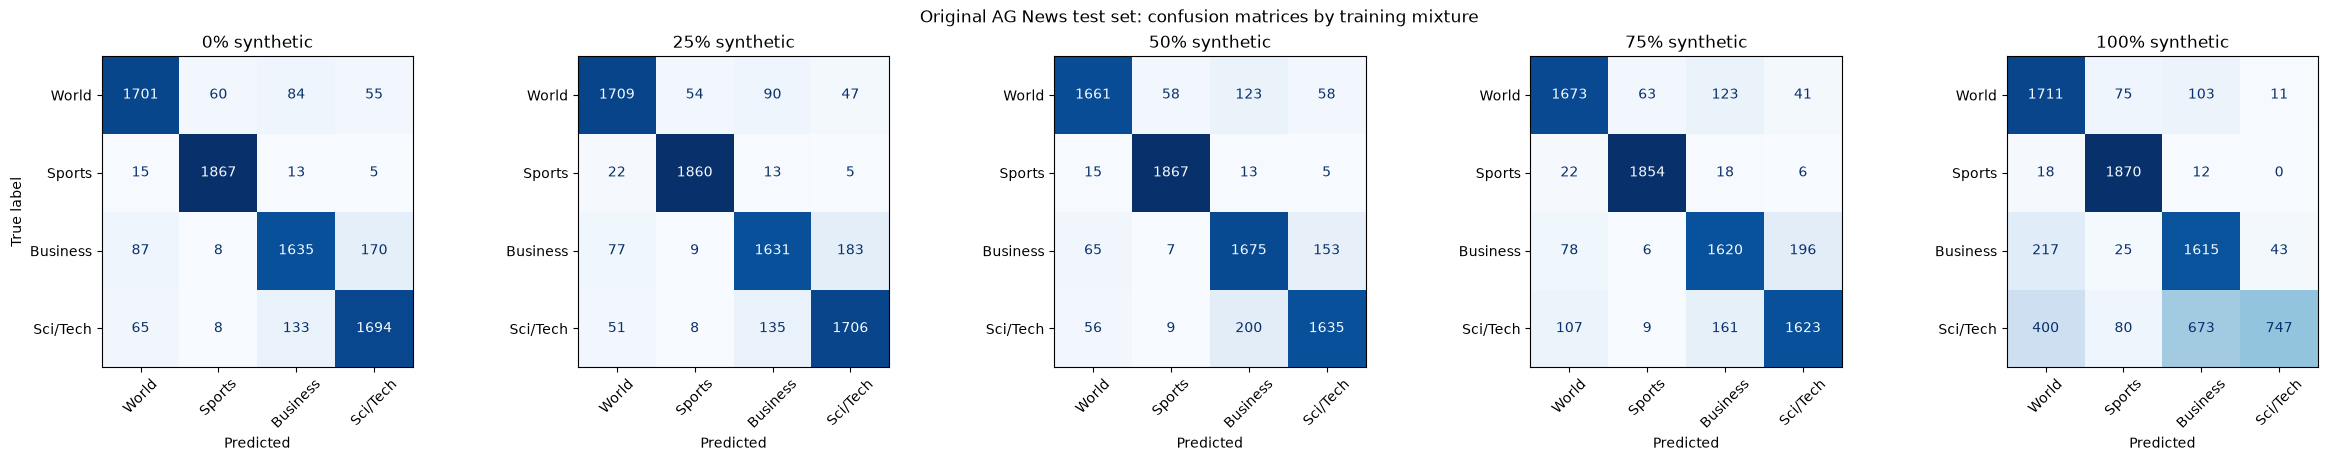

In [5]:
import json
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

percentages = [0, 25, 50, 75, 100]
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5), constrained_layout=True)
for percentage, ax in zip(percentages, axes):
    path = results_dir / f'synthetic_{percentage:03d}' / 'metrics.json'
    result = json.loads(path.read_text(encoding='utf-8'))
    matrix = np.asarray(result['test_confusion_matrix'])
    labels = result['label_names']
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False,
        xticks_rotation=45,
    )
    ax.set_title(f'{percentage}% synthetic')
    ax.set_xlabel('Predicted')
    if percentage != 0:
        ax.set_ylabel('')
fig.suptitle('Original AG News test set: confusion matrices by training mixture')
fig.savefig(results_dir / 'mixture_confusion_matrices.png', dpi=160)
plt.show()